<a href="https://colab.research.google.com/github/mihirgohil1402-ui/Cfd-lab/blob/main/07_Shallow_Water_Wave.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 7: Shallow Water Wave

**Name:** Mihir Gohil  |  **Roll No:** 23BME019  
**Course:** Computational Fluid Dynamics and Heat Transfer Lab (20ME406P), Department of Mechanical Engineering, PDEU


## 1. Aim
To simulate a small wave on still water with the finite volume method, using an explicit and an implicit time scheme, to compare both with the exact solution, and to explain the errors of each (stability, numerical damping, accuracy).

## 2. Problem and parameters
A channel of length L contains water at rest with still-water depth H. At t = 0 the free surface carries a Gaussian hump. The ends of the channel are connected periodically. The hump splits into two pulses of half the amplitude that travel in opposite directions at the wave speed c = √(gH).

| Parameter | Symbol | Value |
|---|---|---|
| Channel length | L | 10 m |
| Still-water depth | H | 1 m |
| Gravity | g | 9.81 m/s² |
| Wave speed | c = √(gH) | 3.132 m/s |
| Hump amplitude | A₀ | 0.08 m |
| Hump width | w | 0.5 m |
| End time | t_end | 0.8 s |
| Base grid | N | 200 cells (Δx = 0.05 m) |
| Base Courant number | Co = cΔt/Δx | 0.8 (explicit), 4 (implicit) |

## 3. Governing equations and method
Linear, non-dispersive, frictionless shallow-water flow in one dimension:
$$\frac{\partial \eta}{\partial t} + H\frac{\partial u}{\partial x} = 0, \qquad \frac{\partial u}{\partial t} + g\frac{\partial \eta}{\partial x} = 0$$

Staggered finite volume grid: η at the cell centres and u at the cell faces (u_i sits on the face to the right of cell i). Then
$$\frac{d\eta_i}{dt} = -H\frac{u_i-u_{i-1}}{\Delta x}, \qquad \frac{du_i}{dt} = -g\frac{\eta_{i+1}-\eta_i}{\Delta x}$$

- **Explicit (forward–backward):** update u from the old η, then update η from the new u. Stable for Co ≤ 1.
- **Implicit (backward Euler):** both equations are written at the new time level and the 2N × 2N sparse system is solved at every step. Stable for any Co, but strongly damping.

**Exact solution** (d'Alembert, periodic): the initial hump splits into two halves,
$$\eta(x,t) = \tfrac12\left[\eta_0(x-ct) + \eta_0(x+ct)\right]$$
with η₀ repeated periodically.

In [ ]:
import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spla
import matplotlib.pyplot as plt
import pandas as pd

L, H, g = 10.0, 1.0, 9.81
A0, w = 0.08, 0.5
t_end = 0.8
c = np.sqrt(g*H)

def eta0(x):
    out = np.zeros_like(x)
    for k in range(-2, 3):                       # periodic images
        out += A0*np.exp(-((x - L/2 - k*L)/w)**2)
    return out

def exact(x, t):
    return 0.5*(eta0(x - c*t) + eta0(x + c*t))

def run(N, Co, scheme):
    dx = L/N
    n_steps = int(np.ceil(t_end/(Co*dx/c)))
    dt = t_end/n_steps                           # land exactly on t_end
    x = (np.arange(N)+0.5)*dx
    eta = eta0(x)
    u = np.zeros(N)
    if scheme == 'explicit':
        for _ in range(n_steps):
            u = u - g*dt/dx*(np.roll(eta, -1) - eta)
            eta = eta - H*dt/dx*(u - np.roll(u, 1))
    else:
        I = sp.identity(N, format='csr')
        Dm = sp.diags([-np.ones(N), np.ones(N)], [0, 1], shape=(N, N), format='lil')
        Dm[N-1, 0] = 1                           # periodic wrap
        Dm = Dm.tocsr()                          # (eta_{i+1} - eta_i) -> d eta / dx on faces
        # d eta/dt = -H/dx (u_i - u_{i-1}) = +H/dx * (Dm^T u)
        # d u /dt  = -g/dx (eta_{i+1} - eta_i) = -g/dx * (Dm eta)
        M = sp.bmat([[None, H/dx*Dm.T], [-g/dx*Dm, None]], format='csc')
        lu = spla.splu((sp.identity(2*N, format='csc') - dt*M).tocsc())
        q = np.concatenate([eta, u])
        for _ in range(n_steps):
            q = lu.solve(q)
        eta, u = q[:N], q[N:]
    return x, eta, dt, n_steps

def metrics(x, eta):
    ex = exact(x, t_end)
    l2 = np.sqrt(np.mean((eta-ex)**2))/A0
    right = x > L/2
    peak = eta[right].max()
    return l2, peak

## 4. Base case

Explicit: Co = 0.8, dt = 0.01270, steps = 63, relative L2 error = 0.0066, peak = 0.0401 m
Implicit: Co = 4.0, dt = 0.06154, steps = 13, relative L2 error = 0.0947, peak = 0.0186 m
Exact peak of each pulse = 0.0400 m


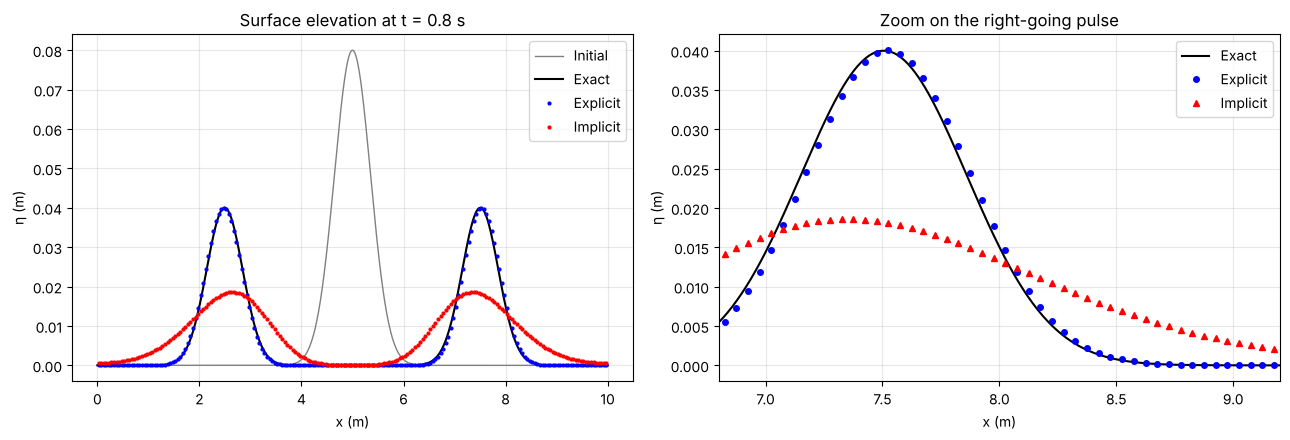

In [ ]:
N = 200
x, e_e, dt_e, n_e = run(N, 0.8, 'explicit')
_, e_i, dt_i, n_i = run(N, 4.0, 'implicit')
xf = np.linspace(0, L, 2000)

print(f"Explicit: Co = 0.8, dt = {dt_e:.5f}, steps = {n_e}, relative L2 error = {metrics(x, e_e)[0]:.4f}, peak = {metrics(x, e_e)[1]:.4f} m")
print(f"Implicit: Co = 4.0, dt = {dt_i:.5f}, steps = {n_i}, relative L2 error = {metrics(x, e_i)[0]:.4f}, peak = {metrics(x, e_i)[1]:.4f} m")
print(f"Exact peak of each pulse = {A0/2:.4f} m")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(xf, eta0(xf), 'gray', lw=1, label='Initial')
ax[0].plot(xf, exact(xf, t_end), 'k-', label='Exact')
ax[0].plot(x, e_e, 'b.', ms=4, label='Explicit')
ax[0].plot(x, e_i, 'r.', ms=4, label='Implicit')
ax[0].set(xlabel='x (m)', ylabel='η (m)', title=f'Surface elevation at t = {t_end} s'); ax[0].legend(); ax[0].grid(alpha=0.3)
ax[1].plot(xf, exact(xf, t_end), 'k-', label='Exact')
ax[1].plot(x, e_e, 'bo', ms=4, label='Explicit')
ax[1].plot(x, e_i, 'r^', ms=4, label='Implicit')
ax[1].set(xlim=(6.8, 9.2), xlabel='x (m)', ylabel='η (m)', title='Zoom on the right-going pulse'); ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 5. Effect of the Courant number

In [ ]:
rows = []
for Co in (0.2, 0.5, 0.8, 0.95, 1.05, 1.5):
    x, e, dt, n = run(200, Co, 'explicit')
    l2, pk = metrics(x, e)
    rows.append(['explicit', Co, dt, n, l2 if np.isfinite(l2) and l2 < 1e3 else float('inf'), pk if np.isfinite(pk) and pk < 1e3 else float('inf')])
for Co in (0.8, 2, 4, 8, 16):
    x, e, dt, n = run(200, Co, 'implicit')
    l2, pk = metrics(x, e)
    rows.append(['implicit', Co, dt, n, l2, pk])
pd.DataFrame(rows, columns=['scheme', 'Co', 'dt', 'steps', 'relative L2 error', 'pulse peak (m)'])

,scheme,Co,dt,steps,relative L2 error,pulse peak (m)
0,explicit,0.20,0.003187,251,0.001117,0.039934
1,explicit,0.50,0.007921,101,0.003619,0.040000
2,explicit,0.80,0.012698,63,0.006648,0.040062
3,explicit,0.95,0.015094,53,0.008269,0.040088
4,explicit,1.05,0.016667,48,0.009368,0.040101
5,explicit,1.50,0.023529,34,inf,inf
6,implicit,0.80,0.012698,63,0.041349,0.029899
7,implicit,2.00,0.030769,26,0.070096,0.023568
8,implicit,4.00,0.061538,13,0.094655,0.018572
9,implicit,8.00,0.114286,7,0.115338,0.014746


## 6. Effect of grid size (Co = 0.8 explicit, Co = 4 implicit)

In [ ]:
rows = []
for Nc in (100, 200, 400, 800):
    xe, ee, _, _ = run(Nc, 0.8, 'explicit')
    xi, ei, _, _ = run(Nc, 4.0, 'implicit')
    rows.append([Nc, L/Nc, metrics(xe, ee)[0], metrics(xe, ee)[1], metrics(xi, ei)[0], metrics(xi, ei)[1]])
pd.DataFrame(rows, columns=['N', 'dx', 'explicit L2 error', 'explicit peak', 'implicit L2 error', 'implicit peak'])

,N,dx,explicit L2 error,explicit peak,implicit L2 error,implicit peak
0,100,0.1000,0.012263,0.040197,0.115387,0.014739
1,200,0.0500,0.006648,0.040062,0.094655,0.018572
2,400,0.0250,0.003420,0.040015,0.070081,0.023570
3,800,0.0125,0.001742,0.040001,0.047594,0.028473


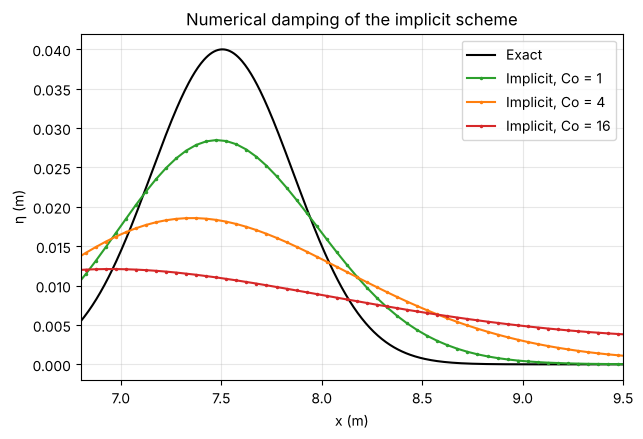

In [ ]:
# Pulse shape at three Courant numbers for the implicit scheme
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(xf, exact(xf, t_end), 'k-', label='Exact')
for Co, col in zip((1, 4, 16), ('tab:green', 'tab:orange', 'tab:red')):
    xx, ee, _, _ = run(200, Co, 'implicit')
    ax.plot(xx, ee, '.-', ms=3, color=col, label=f'Implicit, Co = {Co}')
ax.set(xlim=(6.8, 9.5), xlabel='x (m)', ylabel='η (m)', title='Numerical damping of the implicit scheme'); ax.legend(); ax.grid(alpha=0.3)
plt.show()